In [1]:
import pandas as pd
import numpy as np

from sklearn.datasets import load_breast_cancer

# Load Breast Cancer Wisconsin Dataset
cancer = load_breast_cancer()

# Convert dataset into DataFrame
df = pd.DataFrame(
    cancer.data,
    columns=cancer.feature_names
)

df["target"] = cancer.target

print("Dataset Loaded Successfully!")
print("Dataset Shape:", df.shape)

display(df.head())

Dataset Loaded Successfully!
Dataset Shape: (569, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [3]:
X = df.drop(columns=["target"])
y = df["target"]

print("Input Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nTarget Classes:")
print(cancer.target_names)

print("\nClass Distribution:")
print(y.value_counts().rename(index={
    0: "Malignant",
    1: "Benign"
}))

Input Features Shape: (569, 30)
Target Shape: (569,)

Target Classes:
['malignant' 'benign']

Class Distribution:
target
Benign       357
Malignant    212
Name: count, dtype: int64


In [4]:
print("Missing Values:", df.isnull().sum().sum())
print("Duplicate Rows:", df.duplicated().sum())

print("\nDataset Information:")
df.info()

Missing Values: 0
Duplicate Rows: 0

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error            

In [5]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)
print("Training Labels:", y_train.shape)
print("Testing Labels:", y_test.shape)

Training Features: (455, 30)
Testing Features: (114, 30)
Training Labels: (455,)
Testing Labels: (114,)


In [6]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=10000, random_state=42)
)

model.fit(X_train, y_train)

print("Logistic Regression Model Trained Successfully!")

Logistic Regression Model Trained Successfully!


In [7]:
y_pred = model.predict(X_test)

results = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred
})

results["Actual Class"] = results["Actual"].map({
    0: "Malignant",
    1: "Benign"
})

results["Predicted Class"] = results["Predicted"].map({
    0: "Malignant",
    1: "Benign"
})

display(results.head(10))

,Actual,Predicted,Actual Class,Predicted Class
256,0,0,Malignant,Malignant
428,1,1,Benign,Benign
501,0,0,Malignant,Malignant
363,1,1,Benign,Benign
564,0,0,Malignant,Malignant
464,1,1,Benign,Benign
358,1,1,Benign,Benign
343,0,0,Malignant,Malignant
516,0,0,Malignant,Malignant
567,0,0,Malignant,Malignant


In [8]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

cm = confusion_matrix(y_test, y_pred)

print("===== Logistic Regression Evaluation =====")
print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1-Score :", round(f1, 4))

print("\nConfusion Matrix:")
print(cm)

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=cancer.target_names
))

===== Logistic Regression Evaluation =====
Accuracy : 0.9825
Precision: 0.9861
Recall   : 0.9861
F1-Score : 0.9861

Confusion Matrix:
[[41  1]
 [ 1 71]]

Classification Report:
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



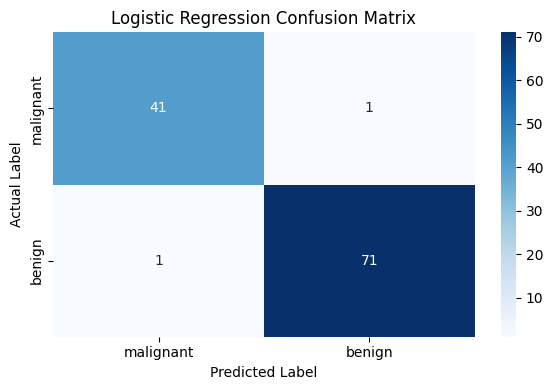

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=cancer.target_names,
    yticklabels=cancer.target_names
)

plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

In [10]:
import pandas as pd
import numpy as np

from sklearn.datasets import load_iris

iris = load_iris()

df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

df["target"] = iris.target
df["species"] = df["target"].map(
    dict(enumerate(iris.target_names))
)

print("Dataset Loaded Successfully!")
print("Dataset Shape:", df.shape)

display(df.head())

Dataset Loaded Successfully!
Dataset Shape: (150, 6)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


In [11]:
X = df[iris.feature_names]
y = df["target"]

print("Input Features:", list(X.columns))
print("Input Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nSpecies Distribution:")
print(df["species"].value_counts())

Input Features: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Input Features Shape: (150, 4)
Target Shape: (150,)

Species Distribution:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


In [13]:
print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nFeature Statistics:")
display(X.describe())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    int64  
 5   species            150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB

Missing Values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
species              0
dtype: int64

Duplicate Rows: 1

Feature Statistics:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [14]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training Set:", X_train_scaled.shape)
print("Testing Set:", X_test_scaled.shape)
print("Feature Scaling Completed!")

Training Set: (120, 4)
Testing Set: (30, 4)
Feature Scaling Completed!


In [15]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

k_values = [3, 5, 7]

models = {}
predictions = {}
confusion_matrices = {}
results = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)

    y_pred = knn.predict(X_test_scaled)

    models[k] = knn
    predictions[k] = y_pred
    confusion_matrices[k] = confusion_matrix(y_test, y_pred)

    accuracy = accuracy_score(y_test, y_pred)

    results.append({
        "K Value": k,
        "Accuracy": round(accuracy, 4),
        "Accuracy (%)": round(accuracy * 100, 2)
    })

    print(f"\n===== KNN with K = {k} =====")
    print("Accuracy:", round(accuracy, 4))
    print("Confusion Matrix:")
    print(confusion_matrices[k])


===== KNN with K = 3 =====
Accuracy: 0.9333
Confusion Matrix:
[[10  0  0]
 [ 0 10  0]
 [ 0  2  8]]

===== KNN with K = 5 =====
Accuracy: 0.9333
Confusion Matrix:
[[10  0  0]
 [ 0 10  0]
 [ 0  2  8]]

===== KNN with K = 7 =====
Accuracy: 0.9667
Confusion Matrix:
[[10  0  0]
 [ 0 10  0]
 [ 0  1  9]]


In [16]:
comparison = pd.DataFrame(results)

display(comparison)

best_accuracy = comparison["Accuracy"].max()

best_k_values = comparison.loc[
    comparison["Accuracy"] == best_accuracy,
    "K Value"
].tolist()

best_k = best_k_values[0]

print("Best K Value:", best_k)
print("Best Accuracy:", round(best_accuracy * 100, 2), "%")

if len(best_k_values) > 1:
    print("Note: Multiple K values achieved the same best accuracy.")

,K Value,Accuracy,Accuracy (%)
0,3,0.9333,93.33
1,5,0.9333,93.33
2,7,0.9667,96.67


Best K Value: 7
Best Accuracy: 96.67 %


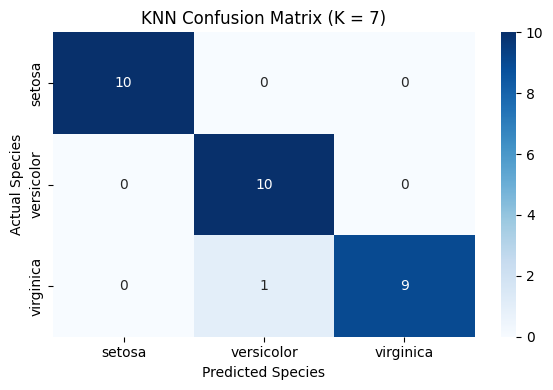

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

best_cm = confusion_matrices[best_k]

plt.figure(figsize=(6, 4))

sns.heatmap(
    best_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.title(f"KNN Confusion Matrix (K = {best_k})")
plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.tight_layout()
plt.show()

In [18]:
import pandas as pd
import numpy as np

from sklearn.datasets import load_breast_cancer

cancer = load_breast_cancer()

df = pd.DataFrame(
    cancer.data,
    columns=cancer.feature_names
)

df["target"] = cancer.target

print("Dataset Shape:", df.shape)
display(df.head())

Dataset Shape: (569, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [19]:
X = df.drop(columns=["target"])
y = df["target"]

print("Input Features Shape:", X.shape)
print("Target Shape:", y.shape)
print("\nTarget Classes:", cancer.target_names)

print("\nClass Distribution:")
print(y.value_counts().rename(index={
    0: "Malignant",
    1: "Benign"
}))

Input Features Shape: (569, 30)
Target Shape: (569,)

Target Classes: ['malignant' 'benign']

Class Distribution:
target
Benign       357
Malignant    212
Name: count, dtype: int64


In [20]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Set:", X_train.shape)
print("Testing Set:", X_test.shape)

Training Set: (455, 30)
Testing Set: (114, 30)


In [21]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

svm_model = make_pipeline(
    StandardScaler(),
    SVC(kernel="rbf")
)

svm_model.fit(X_train, y_train)

print("SVM Model Trained Successfully!")

SVM Model Trained Successfully!


In [22]:
y_pred_svm = svm_model.predict(X_test)

print("Actual Labels (first 10):")
print(y_test.iloc[:10].to_list())

print("\nPredicted Labels (first 10):")
print(y_pred_svm[:10])

Actual Labels (first 10):
[0, 1, 0, 1, 0, 1, 1, 0, 0, 0]

Predicted Labels (first 10):
[0 1 0 1 0 1 1 0 0 0]


In [23]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

svm_accuracy = accuracy_score(y_test, y_pred_svm)
svm_precision = precision_score(y_test, y_pred_svm)
svm_recall = recall_score(y_test, y_pred_svm)
svm_f1 = f1_score(y_test, y_pred_svm)

svm_cm = confusion_matrix(y_test, y_pred_svm)

print("===== SVM Evaluation =====")
print("Accuracy :", round(svm_accuracy, 4))
print("Precision:", round(svm_precision, 4))
print("Recall   :", round(svm_recall, 4))
print("F1-Score :", round(svm_f1, 4))

print("\nConfusion Matrix:")
print(svm_cm)

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_svm,
    target_names=cancer.target_names
))

===== SVM Evaluation =====
Accuracy : 0.9825
Precision: 0.9861
Recall   : 0.9861
F1-Score : 0.9861

Confusion Matrix:
[[41  1]
 [ 1 71]]

Classification Report:
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



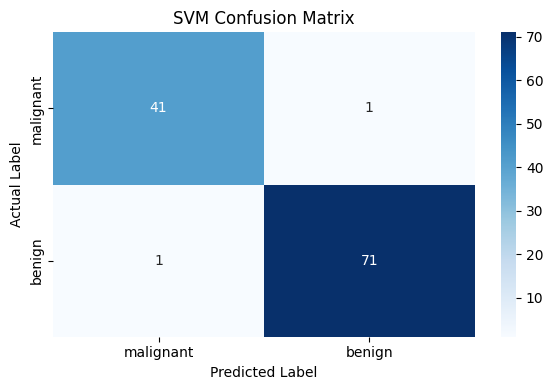

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 4))

sns.heatmap(
    svm_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=cancer.target_names,
    yticklabels=cancer.target_names
)

plt.title("SVM Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

In [25]:
from sklearn.linear_model import LogisticRegression

lr_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=10000, random_state=42)
)

lr_model.fit(X_train, y_train)
y_pred_lr = lr_model.predict(X_test)

lr_results = {
    "Accuracy": accuracy_score(y_test, y_pred_lr),
    "Precision": precision_score(y_test, y_pred_lr),
    "Recall": recall_score(y_test, y_pred_lr),
    "F1-Score": f1_score(y_test, y_pred_lr)
}

svm_results = {
    "Accuracy": svm_accuracy,
    "Precision": svm_precision,
    "Recall": svm_recall,
    "F1-Score": svm_f1
}

comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-Score"],
    "Logistic Regression": [
        lr_results["Accuracy"],
        lr_results["Precision"],
        lr_results["Recall"],
        lr_results["F1-Score"]
    ],
    "SVM": [
        svm_results["Accuracy"],
        svm_results["Precision"],
        svm_results["Recall"],
        svm_results["F1-Score"]
    ]
})

display(comparison.round(4))

print("\nComparison based on Accuracy:")
if svm_accuracy > lr_results["Accuracy"]:
    print("SVM performed better based on Accuracy.")
elif svm_accuracy < lr_results["Accuracy"]:
    print("Logistic Regression performed better based on Accuracy.")
else:
    print("Both models achieved the same Accuracy.")

,Metric,Logistic Regression,SVM
0,Accuracy,0.9825,0.9825
1,Precision,0.9861,0.9861
2,Recall,0.9861,0.9861
3,F1-Score,0.9861,0.9861



Comparison based on Accuracy:
Both models achieved the same Accuracy.
